In [1]:
import requests
import json
import pandas as pd
import numpy as np
import os
from datetime import datetime

with open("keys.json") as f:
    data = json.loads(f.read())
    STEAM_DATA_API = data["STEAM_DATA_API"] 
    STEAM_WEB_API = data["STEAM_WEB_API"] 

BASE_URL = "https://www.steamwebapi.com/steam/"
DT_ISO8601_FORMAT = "%Y-%m-%d %H:%M:%S"

In [ ]:
def call(method: str, call_path: str, extra_params: str | None = None, payload: dict | None = None, base_url = BASE_URL):
    """
    calls the Steam Web API, stores the response to /data/steam_web_api, returns (location of saved file, errorcode)
    """
    method = method.upper()
    body = ""
    headers = {}

    request_url = base_url + call_path + "?key=" + STEAM_WEB_API 

    output_path = f"data/steam_web_api/{call_path.replace('/', '_')}"
    output_path = output_path[:output_path.find("markets")].rstrip()

    if extra_params != None:
        request_url = request_url + "&" + extra_params
        output_path = output_path + "_" + extra_params + "_" + str(datetime.now()) + ".json"

    if payload:
        body = json.dumps(payload)


    if method != "GET" and payload:
        headers["Content-Type"] = "application/json"

    try:
        r = requests.request(
            method,
            request_url,
            headers=headers,
            data=body.encode() if body else None,
            timeout=15,
        )
        r.raise_for_status()
        data_json = r.json()

        if len(data_json) == 0:
            return output_path, "RESPONSE EMPTY"
        
        with open(output_path, "x") as f:
            json.dump(data_json, f, indent=4)

        return output_path, None
    except requests.RequestException as e:
        detail = e.response.text if e.response is not None else "no body"
        return output_path, f"{e} — {detail}"


def getJsonFileasFlatMappedDataFrame(file_path):
    return pd.json_normalize(json.loads(open(file_path).read()))

def getJsonObjAsFlatMappedDataFrame(object):
    return pd.json_normalize(object)

def getData(call_name: str, file_name: str):
    """
    calls the Steam Data API, stores the response to /data/steam_data_api, returns (location of saved file, errorcode)
    """
    headers = {
        "Authorization": f"Bearer {STEAM_DATA_API}",
    }

    try:
        response = requests.get(
            call_name,
            headers=headers,
        )

        response.raise_for_status()
        data = response.json()
        file_name = file_name + "_" + str(datetime.now()) + ".json"
        with open(file_name, "x") as f:
            json.dump(data,f, indent=4)

        print(f"File: {file_name}" +  ", Size: " + str(os.path.getsize(file_name)/1000) + "KB" )
        return 0
    
    except requests.RequestException as e:
        detail = e.response.text if e.response is not None else "no body"
        print(f"{e} — {detail}")
        return 1

# API Aufrufe

In [24]:
call_path = "api/items"
game_param = "game=cs2"

full_params = game_param + '&' + 'page=0'
location, errorcode = call("GET", call_path, full_params)
if (errorcode != None):
    print(errorcode)
print(f"File: {location}" +  ", Size: " + str(os.path.getsize(location)/1000) + "KB")


FileExistsError: [Errno 17] File exists: 'data/steam_web_api/api_item_game=cs2&page=0.json'

In [ ]:
call_path = "https://steamdataapi.com/api/v1/items/all?game=cs2&markets=1&variants=1&&currency=USD"
file_name = "data/steam_data_api/all_items_"

errorcode = getData(call_path, file_name)

File: data/steam_data_api/all_items_meta_2026-11-20 12:09:23.273499.json, Size: 148751.332KB


In [ ]:
for pageNum in range(1,62):
    call_path = f"https://steamdataapi.com/api/v1/buy-orders?game=cs2&limit=500&page={pageNum}&currency=USD"
    file_name = f"data/buy_orders_page_{pageNum}"
    errorcode = getData(call_path, file_name)
    if errorcode == 1:
        break

# Datenexploration der Verkaufsangebote

In [3]:
def remove_0_prices(df: pd.DataFrame):
    """
    Aufgrund von abrundung werden manche preise > 1 cent als 0 zurückgegeben
    -> bei kauf würden diese aber auf 1 cent aufgerundet werden
    """
    df.loc[df["price"] == 0, 'price'] = 1

def organize_columns(df: pd.DataFrame):
    """
    Löschen von unnötigen Spalten & umbenennung
    """
    df = df[["marketHashName","sold24h","markets","variants"]]
    df = df.rename(columns={"sold24h":"steam_sales_last_24h"})
    return df

def add_captured_at_to_variants_df(df: pd.DataFrame):
    df = df.explode("markets").dropna(subset=["markets"]).reset_index(drop=True)
    market_details = pd.json_normalize(df["markets"])
    variant_cols = "capturedAt"
    return pd.concat([df.drop(columns=["markets"]), market_details[variant_cols]], axis=1).drop_duplicates(subset="marketHashName")


def divide_df_based_on_variants(df: pd.DataFrame):
    """
    Trennt items in zwei dataframes, eins enthält json object mit variants informationen, anderes enthält keine variants 
    """
    has_variants = df["variants"].notna() & (df["variants"].str.len() > 0)
    df_no_var = df[~has_variants].drop(columns=["variants"])
    df_no_var["variant"] = "N"

    df_var = df[has_variants]
    df_var = add_captured_at_to_variants_df(df_var)

    return df_no_var, df_var


def extract_variants(df: pd.DataFrame):
    """
    json objekt in variants spalte wird exploded & normalisiert -> eine zeile pro variante
    """
    df = df.explode("variants").reset_index(drop=True)
    variant_details = pd.json_normalize(df["variants"])
    variant_cols = [c for c in ["variant", "markets"] if c in variant_details.columns]
    return pd.concat([df.drop(columns=["variants"]), variant_details[variant_cols]], axis=1)

def extract_markets(df: pd.DataFrame):
    """
    markt dictionaries in markets spalte werden exploded & normalisiert -> eine zeile pro markt, da es unterschiedliche namensgebungen zwischen den varianten markets und den no_variant markets gibt, werden die namen normalisiert (updatedAt / capturedAt -> capturedAt)
    """
    df = df.explode("markets").dropna(subset=["markets"]).reset_index(drop=True)
    market_details = pd.json_normalize(df["markets"])
    return pd.concat(
        [
            df.drop(columns=["markets"]),
            market_details.drop(columns=["icon", "updatedAt"], errors="ignore"),
        ],
        axis=1,
    )

def normalize_sell_orders(df: pd.DataFrame):
    """
    1. schauen ob varianten existieren oder nicht
    2. wenn varianten existieren, exploden & normalisieren, jede variante hat wieder eigene markets liste
    3. varianten namen umbennen, da quantityUpdatedAt / updatedAt/capturedAt nicht gleich genannt werden 
    4. alle zusammenfügen & market exploden & normalisieren
    """
    df = organize_columns(df)

    df_no_var, df_var = divide_df_based_on_variants(df)

    df_no_var = extract_markets(df_no_var)

    if not df_var.empty:
        df_var = extract_variants(df_var)
        df_var = extract_markets(df_var)

        combined_df = pd.concat([df_no_var, df_var], ignore_index=True)
    else:
        combined_df = df_no_var.reset_index(drop=True)

    remove_0_prices(combined_df)
    combined_df["capturedAt"] = pd.to_datetime(combined_df["capturedAt"], format='ISO8601', utc=True)  
    combined_df["priceUpdatedAt"] = pd.to_datetime(pd.Timestamp.now("UTC"), format='ISO8601', utc=True)  

    return combined_df


def normalize_sell_orders_drop_variants(df: pd.DataFrame):
    df = organize_columns(df)

    has_variants = df["variants"].notna() & (df["variants"].str.len() > 0)
    df = df[~has_variants].drop(columns=["variants"])
    df = extract_markets(df)
    remove_0_prices(df)
    df["capturedAt"] = pd.to_datetime(df["capturedAt"], format='ISO8601', utc=True)  
    df["priceUpdatedAt"] = pd.to_datetime(pd.Timestamp.now("UTC"), format='ISO8601', utc=True)  

    return df
       

In [4]:
all_items_file_alt = json.loads(open("data/steam_data_api/all_items_no_info_2026-11-17 13:44:47.776898.json").read())
verkaufs_angebote_alt = getJsonObjAsFlatMappedDataFrame(all_items_file_alt["data"])

#all_items_file_neu = json.loads(open("data/steam_data_api/all_items_no_info_2026-11-17 18:05:45.603960.json").read())
#verkaufs_angebote_neu = getJsonObjAsFlatMappedDataFrame(all_items_file_neu["data"])

verkaufs_angebote_alt = normalize_sell_orders(verkaufs_angebote_alt)
#verkaufs_angebote_neu = normalize_sell_orders(verkaufs_angebote_neu)

In [44]:
dt_verkaufs_angebote_alt = "2026-11-17 13:44:47"
dt_verkaufs_angebote_neu = "2026-11-17 18:05:45"

dt_verkaufs_angebote_alt = pd.to_datetime(datetime.strptime(dt_verkaufs_angebote_alt, DT_ISO8601_FORMAT), format='ISO8601', utc=True) 
dt_verkaufs_angebote_neu = pd.to_datetime(datetime.strptime(dt_verkaufs_angebote_neu, DT_ISO8601_FORMAT), format='ISO8601', utc=True) 

In [45]:
verkaufs_angebote_alt.head()

,marketHashName,steam_sales_last_24h,variant,market,price,quantity,capturedAt,priceUpdatedAt
0,'Blueberries' Buckshot | NSWC SEAL,17.0,N,avan,936,216.0,2026-11-17 13:43:09.578000+00:00,2026-11-20 13:26:39.009969+00:00
1,'Blueberries' Buckshot | NSWC SEAL,17.0,N,buff163,897,187.0,2026-11-17 13:44:25.468000+00:00,2026-11-20 13:26:39.009969+00:00
2,'Blueberries' Buckshot | NSWC SEAL,17.0,N,c5game,926,263.0,2026-11-17 13:44:25.468000+00:00,2026-11-20 13:26:39.009969+00:00
3,'Blueberries' Buckshot | NSWC SEAL,17.0,N,csfloat,930,190.0,2026-11-17 13:40:20.942000+00:00,2026-11-20 13:26:39.009969+00:00
4,'Blueberries' Buckshot | NSWC SEAL,17.0,N,csmoney,909,95.0,2026-11-17 13:44:01.373000+00:00,2026-11-20 13:26:39.009969+00:00


# 1. Vollständigkeit 

-> Wie viele einzigartige Skin+varianten haben Verkaufsangebote auf mehr als einem Markt

In [53]:
unique_columns = ["marketHashName", "variant", "market"]

# 1. Alle möglichen Zeilen
print(f"Count verkaufs_angebote_alt: {verkaufs_angebote_alt.shape[0]}")
print(f"Count verkaufs_angebote_neu: {verkaufs_angebote_neu.shape[0]} \n")

#2. Einzigarte Entries (name + variante + markt)
print(f"Count Angebote ohne Duplikate alt: {verkaufs_angebote_alt[unique_columns].drop_duplicates().shape[0]}")
print(f"Count Angebote ohne Duplikate neu: {verkaufs_angebote_neu[unique_columns].drop_duplicates().shape[0]} \n")

#3. Insgesamt alle möglichen skin + variant möglichkeiten
unique_columns = ["marketHashName", "variant"]
print(f"Count Alle skin+variant möglichkeiten alt: {verkaufs_angebote_alt[unique_columns].drop_duplicates().shape[0]}")
print(f"Count Alle skin+variant möglichkeiten neu: {verkaufs_angebote_neu[unique_columns].drop_duplicates().shape[0]} \n")

#3. Skin + variant möglichkeiten, mit Angeboten auf mind 2 platformen
print(f"Count Alle skin+variant möglichkeiten mit >= 2 Plattformen alt: {(verkaufs_angebote_alt.groupby(unique_columns)['market'].nunique() >= 2).shape[0]}")
print(f"Count Alle skin+variant möglichkeiten mit >= 2 Plattformen neu: {(verkaufs_angebote_neu.groupby(unique_columns)['market'].nunique() >= 2).shape[0]}")

Count verkaufs_angebote_alt: 392998
Count verkaufs_angebote_neu: 392415 

Count Angebote ohne Duplikate alt: 392998
Count Angebote ohne Duplikate neu: 392415 

Count Alle skin+variant möglichkeiten alt: 31807
Count Alle skin+variant möglichkeiten neu: 31809 

Count Alle skin+variant möglichkeiten mit >= 2 Plattformen alt: 31807
Count Alle skin+variant möglichkeiten mit >= 2 Plattformen neu: 31809


# 2. Eindeutingkeit
Gibt es duplikate für einen Eintrag ? (HashName + Variante + Markt)

In [132]:
subset_cols  = ['marketHashName', 'variant', 'market']

print(f" Duplizierte Einträge alt: {verkaufs_angebote_alt.duplicated(subset=subset_cols).sum()}")
print(f" Duplizierte Einträge neu: {verkaufs_angebote_neu.duplicated(subset=subset_cols).sum()}")

 Duplizierte Einträge alt: 0
 Duplizierte Einträge neu: 0


# 3. Plausibilität 

Wo liegen die Preisunterschiede? 
-> CS Markt sehr Volatil, also vergleich mit einer anderen Aggregator API

In [9]:
def get_aggregated_price_info(df: pd.DataFrame)-> pd.DataFrame:
     # Group pro item & Aggregate Prices, also build interesting statistical values
     price_stats = (df
                    .groupby(["marketHashName", "variant"], dropna=False)['price']
                    .agg(market_count = 'count',
                         min_price = 'min',
                         median_price = 'median',
                         max_price = 'max',
                         std_price = 'std').reset_index())


     price_stats['abs_spread'] = price_stats['max_price'] - price_stats['min_price']
     price_stats['rel_spread_pct'] = (price_stats['abs_spread'] / price_stats['min_price']) * 100
     price_stats['extreme_spreads'] = (price_stats['rel_spread_pct'] > 100)

     price_stats = price_stats[price_stats["market_count"] >= 2]
     return price_stats

In [ ]:
price_stats = get_aggregated_price_info(verkaufs_angebote_alt)
extreme_spreads = price_stats[price_stats['extreme_spreads']]
print(f"Items with spread between Platforms over 100% {extreme_spreads.shape[0]}")
print(f"Items without Spread: {price_stats[price_stats['rel_spread_pct'] <= 0].shape[0]}")
print(f"Average Spread across all items: {price_stats['rel_spread_pct'].sum() / price_stats['rel_spread_pct'].shape[0]}")  
print(f"Average Spread across all items: {price_stats['rel_spread_pct'].sum() / price_stats['rel_spread_pct'].shape[0]}")  
price_stats.describe()

Items with spread between Platforms over over 100% 15368
Items without Spread: 12
Average Spread across all items: 138.24164136986423
Average Spread across all items: 138.24164136986423


,market_count,min_price,median_price,max_price,std_price,abs_spread,rel_spread_pct
count,30763.000000,3.076300e+04,3.076300e+04,3.076300e+04,3.076300e+04,3.076300e+04,30763.000000
mean,12.741085,9.512103e+03,1.134734e+04,1.554813e+04,2.133925e+03,6.036022e+03,138.241641
std,3.692441,8.716086e+04,1.227274e+05,1.423139e+05,3.201236e+04,6.605805e+04,112.534786
min,2.000000,1.000000e+00,1.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,11.000000,2.700000e+01,3.550000e+01,5.900000e+01,7.972329e+00,2.700000e+01,40.845070
50%,14.000000,2.420000e+02,3.090000e+02,5.030000e+02,6.235711e+01,2.100000e+02,100.000000
75%,16.000000,2.971000e+03,3.658250e+03,5.289000e+03,5.397751e+02,1.759500e+03,217.108014
max,16.000000,7.500188e+06,1.500038e+07,1.514947e+07,4.553559e+06,8.474303e+06,400.000000


## Pretty big spreads, compare with data from other source (steam web api)

In [16]:
def extract_prices(df: pd.DataFrame):
    df = df.explode("prices").dropna(subset=["prices"]).reset_index(drop=True)
    price_details = pd.json_normalize(df["prices"], max_level=0)
    price_cols = [c for c in ["price", "source", "quantity", "type", "created_at", "variants"] if c in price_details.columns]
    return pd.concat([df.drop(columns=["prices"]), price_details[price_cols]], axis=1)

def extract_variants(df: pd.DataFrame):
    df = df.drop(columns=["price"])
    exploded = df.assign(variants=df["variants"].apply(lambda d: list(d.items()) if isinstance(d, dict) else [])).explode("variants")
    exploded[["variant", "price"]] = pd.DataFrame(exploded["variants"].tolist(), index=exploded.index)
    return exploded.drop(columns=["variants"])

def normalize_web_api_items(df: pd.DataFrame):
    df = df[["markethashname", "priceupdatedat.date", "prices"]]
    df = df.rename(columns={"priceupdatedat.date": "priceupdatedat"})
    has_info = (df["prices"].notna() & (df["prices"].str.len() > 0) & df["priceupdatedat"].notna())
    df = df[has_info]
    
    df = extract_prices(df)

    has_variants = df["variants"].notna()
    no_var = df[~has_variants]
    var = df[has_variants]

    no_var = no_var.drop(columns=["variants"])
    no_var["variant"] = "N"
    
    if not var.empty:
        var = extract_variants(var)
        combined_df = pd.concat([no_var, var], ignore_index=True)
    else:
        combined_df = no_var.reset_index(drop=True)

    remove_0_prices(combined_df)
    combined_df["created_at"] = pd.to_datetime(combined_df["created_at"], format='ISO8601', utc=True)    
    combined_df["priceupdatedat"] = pd.to_datetime(combined_df["priceupdatedat"], format='ISO8601', utc=True)  
    
    combined_df = combined_df.rename(columns={"priceupdatedat": "capturedAt", "created_at": "order_created_at", "markethashname": "marketHashName", "source": "market"})
    combined_df["priceUpdatedAt"] = pd.to_datetime(pd.Timestamp.now("UTC"), format='ISO8601', utc=True)  

    return combined_df

In [17]:
web_api_all_items_file_0 = json.loads(open("data/steam_web_api/api_item_game=cs2&page=0.json").read())
web_items_0 = getJsonObjAsFlatMappedDataFrame(web_api_all_items_file_0) 
web_items_normalized = normalize_web_api_items(web_items_0)

In [18]:
alternative_price_stats = get_aggregated_price_info(web_items_normalized)
extreme_spreads = alternative_price_stats[alternative_price_stats['extreme_spreads']]
print(f"Items with spread between Platforms over 100% {extreme_spreads.shape[0]}")
print(f"Items without Spread: {alternative_price_stats[alternative_price_stats['rel_spread_pct'] <= 0].shape[0]}")
print(f"Average Spread across all items: {alternative_price_stats['rel_spread_pct'].sum() / alternative_price_stats['rel_spread_pct'].shape[0]}")  
alternative_price_stats.describe()

Items with spread between Platforms over 100% 21173
Items without Spread: 13
Average Spread across all items: 1324.741269674489


,market_count,min_price,median_price,max_price,std_price,abs_spread,rel_spread_pct
count,34134.000000,34134.000000,34134.000000,34134.000000,34134.000000,34134.000000,34134.000000
mean,10.658610,82.398158,98.608785,156.677853,28.427266,74.279695,1324.741270
std,3.640765,808.972101,1130.093594,1335.110595,340.086860,716.845980,6811.182401
min,2.000000,0.010000,0.010000,0.020000,0.000000,0.000000,0.000000
25%,8.000000,0.360000,0.540000,2.000000,0.335419,1.030000,50.000000
50%,12.000000,2.530000,3.560000,10.850000,1.863835,5.730000,194.101471
75%,14.000000,22.305000,29.180000,56.030000,8.484844,26.080000,834.890443
max,16.000000,74985.000000,149970.010000,157226.680000,46909.708569,90477.580000,349900.000000


## Ergebnis: Gleich große Unterschiede / Extreme 

1. Kleine centbeträge verändern spread extrem (1 cent vs 3 cent unterschied = 200% spread)

2. Vergleich von Min und Max macht relativ wenig sinn.

Da es sind liegende Angebote sind, also Max preis kann deutlich überzogen sein.

In [22]:
norm = lambda s: s.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
web_items_normalized.loc[web_items_normalized["market"] == "buff", 'market'] = "buff163"

main = verkaufs_angebote_alt.assign(mp=norm(verkaufs_angebote_alt["market"]))
alt  = web_items_normalized.assign(mp=norm(web_items_normalized["market"]))

pm, pa = set(main["mp"]), set(alt["mp"])
common = pm & pa
print(len(pm), len(pa), len(common))
print("only main:", sorted(pm - pa))
print("only alt:", sorted(pa - pm))

sm = get_aggregated_price_info(main[main["mp"].isin(common)])
sa = get_aggregated_price_info(alt[alt["mp"].isin(common)])
print(sm["rel_spread_pct"].describe())
print(sa["rel_spread_pct"].describe())

# 2) where does the alt maximum come from?
g = ["marketHashName", "variant"]
top = alt.loc[alt.groupby(g, dropna=False)["price"].idxmax()]
print(top["mp"].value_counts().head(10))
print("share of alt maxima from platforms the main data also has:", top["mp"].isin(pm).mean())

16 16 9
only main: ['avan', 'c5game', 'csmoney', 'csmoneytrade', 'mannco', 'marketcsgo', 'whitemarket']
only alt: ['49skins', 'csdeals', 'csgocom', 'skinflow', 'skinland', 'skinscom', 'tradeit']
count    30455.000000
mean       115.944902
std        102.652597
min          0.000000
25%         32.364319
50%         79.282869
75%        181.818182
max        400.000000
Name: rel_spread_pct, dtype: float64
count     33916.000000
mean        892.690820
std        4853.819592
min           0.000000
25%          34.210526
50%         110.526316
75%         519.834711
max      230600.000000
Name: rel_spread_pct, dtype: float64
mp
skinflow     6227
csgocom      3616
skinport     3278
skinbaron    3164
dmarket      2761
skinscom     2397
skinland     2366
youpin       2020
tradeit      1861
buff163      1791
Name: count, dtype: int64
share of alt maxima from platforms the main data also has: 0.4828708461801987


In [23]:
ck = ["marketHashName", "variant"]

# A) item-level: items present in both sources, shared platforms only
sm_ = sm.assign(variant=sm["variant"].fillna(""))
sa_ = sa.assign(variant=sa["variant"].fillna(""))
c = sm_.merge(sa_, on=ck, suffixes=("_main", "_alt"))
print(len(sm), len(sa), len(c))
print(c[["rel_spread_pct_main", "rel_spread_pct_alt"]].describe())
print("same platform count:", (c["market_count_main"] == c["market_count_alt"]).mean())
c["min_ratio"] = c["min_price_main"] / 100 / c["min_price_alt"]
c["max_ratio"] = c["max_price_main"] / 100 / c["max_price_alt"]
print(c[["min_ratio", "max_ratio"]].describe())

# B) listing-level: does alt have listings that main lacks, on the same item + platform?
k = ["marketHashName", "variant", "mp"]
m_ = main.assign(variant=main["variant"].fillna(""), usd=main["price"] / 100)
a_ = alt.assign(variant=alt["variant"].fillna(""), usd=alt["price"])
items_main = m_[ck].drop_duplicates()
a_sh = a_[a_["mp"].isin(common)].merge(items_main, on=ck)           # alt, shared platforms, items main knows
chk = a_sh.merge(m_[k].drop_duplicates(), on=k, how="left", indicator=True)
print("alt listings missing in main:", (chk["_merge"] == "left_only").mean())

j = m_[k + ["usd"]].merge(a_[k + ["usd"]], on=k, suffixes=("_main", "_alt"))
j["ratio"] = j["usd_main"] / j["usd_alt"]
print(len(j), "pairs | within 1 cent:", ((j["usd_main"] - j["usd_alt"]).abs() <= 0.011).mean(),
      "| within 5%:", ((j["ratio"] - 1).abs() < .05).mean())
print(j.groupby("mp")["ratio"].agg(["count", "median", lambda s: (s.sub(1).abs() < .05).mean()]))

30455 33916 30062
       rel_spread_pct_main  rel_spread_pct_alt
count         30062.000000        30062.000000
mean            116.444273          906.517800
std             102.706139         5029.677334
min               0.000000            0.000000
25%              32.692308           34.615385
50%              79.794711          105.882353
75%             183.333333          500.000000
max             400.000000       230600.000000
same platform count: 0.63758232985164
          min_ratio     max_ratio
count  30062.000000  30062.000000
mean       1.013169      0.790005
std        0.149347      0.401961
min        0.014200      0.001143
25%        1.000000      0.404164
50%        1.000000      1.000000
75%        1.009362      1.004167
max       13.043478      4.999633
alt listings missing in main: 0.06521114872214342
214850 pairs | within 1 cent: 0.5115336281126367 | within 5%: 0.809881312543635
           count    median  <lambda_0>
mp                                    
buff163

## Verbesserung der Plausabilitätsabfrage (Claude)

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

CENT = 1

def robust_stats(df):
    """ Per item statistiken"""
    s = (df.groupby(["marketHashName", "variant"], dropna=False)["price"]
           .agg(n="count", min_p="min", max_p="max", med="median",
                q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75),
                second_min=lambda x: x.nsmallest(2).iloc[-1] if len(x) > 1 else np.nan)
           .reset_index())
    s["abs_spread"]  = s["max_p"] - s["min_p"]
    s["rel_pct"]     = s["abs_spread"] / s["min_p"] * 100                    # your current metric
    s["log_ratio"]   = np.log(s["max_p"] / s["min_p"])                       # scale-free
    s["sym_pct"]     = s["abs_spread"] / ((s["max_p"] + s["min_p"]) / 2) * 100  # bounded, symmetric
    s["med_pct"]     = s["abs_spread"] / s["med"] * 100                      # denominator = robust level
    s["iqr_pct"]     = (s["q3"] - s["q1"]) / s["med"] * 100                  # ignores outlier platforms
    s["gap12_pct"]   = (s["second_min"] - s["min_p"]) / s["min_p"] * 100     # lowest vs. second lowest
    # rounding: a 1-cent observed spread cannot be told apart from 0
    s["rounding_pct"] = CENT / s["min_p"] * 100                              # rounding-only spread bound
    s["resolvable"]   = s["abs_spread"] > CENT
    return s

def sim_median_spread(n, base, sigma=0.03, reps=5000):
    p = np.maximum(np.round(base * np.exp(rng.normal(0, sigma, (reps, n))), 2), CENT)
    return np.median((p.max(1) - p.min(1)) / p.min(1) * 100)

overall spearman: -0.22884856930315234
                       items  spearman_n  median_rel_pct  median_sym_pct  \
bucket                                                                     
(0.999, 18.0]         5408.0   -0.074186      288.888889      118.181818   
(18.0, 81.5]          5202.0   -0.480721      114.285714       72.727273   
(81.5, 351.0]         5296.0   -0.441113       91.068376       62.575243   
(351.0, 1617.5]       5298.0   -0.326797       92.476360       63.236799   
(1617.5, 9192.0]      5301.0   -0.008485       50.114286       40.073109   
(9192.0, 15000375.0]  5302.0    0.041294       36.575159       30.920536   

                      median_iqr_pct  share_resolvable  
bucket                                                  
(0.999, 18.0]              44.444444          0.998521  
(18.0, 81.5]               14.864865          0.997501  
(81.5, 351.0]              11.974139          0.992069  
(351.0, 1617.5]            12.361111          0.976972  
(1617.5, 9

/tmp/ipykernel_1037/1409851082.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: pd.Series({"items": len(d),


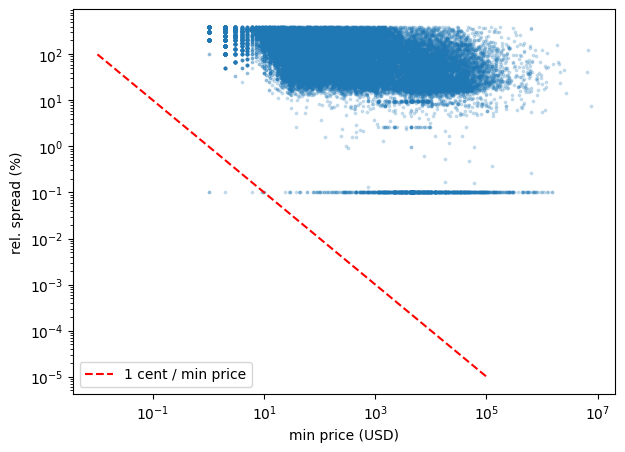

    0.03       0.50       5.00       50.00      500.00
3      0.0   4.166667   4.878049   4.921907   4.847407
8      0.0   8.333333   8.750000   8.785001   8.814280
12     0.0  10.416667  10.041841  10.130060  10.148164
16     0.0  10.638298  11.040340  11.023763  11.079817
items >= 1 USD: 30751 | share with sym_pct > band: 0.9664075965009268 | share with iqr_pct > band: 0.4637247569184742


In [8]:


stats = robust_stats(verkaufs_angebote_alt)
print("overall spearman:", stats["rel_pct"].corr(stats["n"], method="spearman"))
stats["bucket"] = pd.qcut(stats["med"], 6, duplicates="drop")
print(stats.groupby("bucket", observed=True)
           .apply(lambda d: pd.Series({"items": len(d),
                                       "spearman_n": d["rel_pct"].corr(d["n"], method="spearman"),
                                       "median_rel_pct": d["rel_pct"].median(),
                                       "median_sym_pct": d["sym_pct"].median(),
                                       "median_iqr_pct": d["iqr_pct"].median(),
                                       "share_resolvable": d["resolvable"].mean()})))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(stats["min_p"], stats["rel_pct"].clip(lower=0.1), s=3, alpha=.2)
x = np.logspace(-2, 5, 200)
ax.plot(x, CENT / x * 100, "r--", label="1 cent / min price")
ax.set(xscale="log", yscale="log", xlabel="min price (USD)", ylabel="rel. spread (%)")
ax.legend(); plt.show()

rng = np.random.default_rng(0)


null = pd.DataFrame({base: [sim_median_spread(n, base) for n in (3, 8, 12, 16)]
                     for base in (0.03, 0.5, 5, 50, 500)}, index=[3, 8, 12, 16])
print(null)

FEE_BAND_PCT = 15   # placeholder: fill in from the platforms' fee tables
ok = stats[stats["resolvable"] & (stats["min_p"] >= CENT / 0.01)]   # rounding <= 1 %, i.e. min >= 1 USD
print("items >= 1 USD:", len(ok),
      "| share with sym_pct > band:", (ok["sym_pct"] > FEE_BAND_PCT).mean(),
      "| share with iqr_pct > band:", (ok["iqr_pct"] > FEE_BAND_PCT).mean())

# Vergleich 20 zufälliger Reihen mit Preisen auf Marktplatz-Website

In [18]:
import random 
items_meta_file = json.loads(open("data/steam_data_api/all_items_meta_2026-11-20 12:09:23.273499.json").read())
meta_orders = getJsonObjAsFlatMappedDataFrame(items_meta_file["data"])
newest_items = normalize_sell_orders(meta_orders)

In [25]:
random_numbers = random.sample(range(1, newest_items.index.max()), 20)


In [30]:
newest_items.iloc[random_numbers]

,marketHashName,steam_sales_last_24h,variant,market,price,quantity,capturedAt,priceUpdatedAt
40436,Glock-18 | Steel Disruption (Field-Tested),2.0,N,marketcsgo,897,61.0,2026-11-20 12:07:00.859000+00:00,2026-11-20 12:16:05.267715+00:00
346391,★ Flip Knife | Ultraviolet (Battle-Scarred),1.0,N,buff163,10648,9.0,2026-11-20 12:04:22.440000+00:00,2026-11-20 12:16:05.267715+00:00
340705,★ Butterfly Knife | Freehand (Field-Tested),3.0,N,waxpeer,46299,66.0,2026-11-20 12:07:43.800000+00:00,2026-11-20 12:16:05.267715+00:00
325403,Tec-9 | Sandstorm (Battle-Scarred),14.0,N,whitemarket,38,73.0,2026-11-20 12:00:11.572000+00:00,2026-11-20 12:16:05.267715+00:00
308872,Sticker | rallen | Cologne 2015,2.0,N,csfloat,600,4.0,2026-11-20 12:05:20.866000+00:00,2026-11-20 12:16:05.267715+00:00
266553,Sticker | TjP (Gold) | Cologne 2026,1.0,N,c5game,1424,5.0,2026-11-20 12:04:22.440000+00:00,2026-11-20 12:16:05.267715+00:00
10599,AWP | POP AWP (Factory New),1.0,N,waxpeer,2735,136.0,2026-11-20 12:07:43.800000+00:00,2026-11-20 12:16:05.267715+00:00
324216,Tec-9 | Hades (Factory New),2.0,N,csmoney,1887,9.0,2026-11-20 12:09:01.259000+00:00,2026-11-20 12:16:05.267715+00:00
23892,Dual Berettas | Duelist (Battle-Scarred),1.0,N,haloskins,20559,1.0,2026-11-20 12:07:35.302000+00:00,2026-11-20 12:16:05.267715+00:00
200066,StatTrak™ Zeus x27 | Olympus (Factory New),5.0,N,c5game,1433,58.0,2026-11-20 12:04:22.440000+00:00,2026-11-20 12:16:05.267715+00:00


In [ ]:
# Calculation of percent change for the table

alt = 106.48
neu = 106.33
((neu - alt)/ abs(alt)) * 100

-0.14087152516905116

## Ergebnis: Preise sind Akkurat

# 4. Aktualität

Wie alt sind die Angebote? 

In [12]:

time_analyze_df_alt = verkaufs_angebote_alt.copy()
time_analyze_df_neu = verkaufs_angebote_neu.copy()

time_analyze_df_alt["time_between_capture_and_request"] = dt_verkaufs_angebote_alt - time_analyze_df_alt['capturedAt'] #dt_verkaufs_angebote_alt =  Timestamp('2026-11-17 13:44:47+0000', tz='UTC')
time_analyze_df_neu["time_between_capture_and_request"] = dt_verkaufs_angebote_neu - time_analyze_df_neu['capturedAt'] #dt_verkaufs_angebote_neu =  Timestamp('2026-11-17 18:05:45+0000', tz='UTC')


In [13]:
print(time_analyze_df_alt['time_between_capture_and_request'].quantile(0.99))
time_analyze_df_alt['time_between_capture_and_request'].describe()

0 days 00:13:57.402000


count                       392998
mean     0 days 00:03:04.746198263
std      0 days 00:03:26.263127807
min         0 days 00:00:21.532000
25%         0 days 00:00:45.627000
50%         0 days 00:02:11.386000
75%         0 days 00:03:40.457000
max         0 days 01:31:06.026000
Name: time_between_capture_and_request, dtype: object

In [14]:
print(time_analyze_df_neu['time_between_capture_and_request'].quantile(0.99))
time_analyze_df_neu['time_between_capture_and_request'].describe()

0 days 00:05:34.614000


count                       392415
mean     0 days 00:02:46.699852729
std      0 days 00:01:57.957954484
min         0 days 00:00:23.994000
25%         0 days 00:01:17.320000
50%         0 days 00:02:37.376000
75%         0 days 00:04:03.199000
max         0 days 01:52:04.362000
Name: time_between_capture_and_request, dtype: object

# 5. Stabilität über die Zeit (Stability over Time)

Bleiben API responses consistent über unterschiedliche Aufrufe

In [ ]:
# -> durch obere Analysen bewiesen

# 6. Volatilität 

Preis bzw Demandänderungen über die zeit

In [15]:
combined = pd.concat([verkaufs_angebote_alt,verkaufs_angebote_neu], axis=0)
combined.index = range(len(combined))
print(f"Combined = {combined.shape[0]}, addition = {verkaufs_angebote_alt.shape[0] + verkaufs_angebote_neu.shape[0]}")

price_stats = (combined
            .groupby(["marketHashName", "variant", "market"], dropna=False)['price'].agg(first_price = 'first', last_price = 'last').reset_index())

price_stats = price_stats[price_stats['first_price'] != price_stats['last_price']]


quantity_stats = (combined
            .groupby(["marketHashName", "variant", "market"], dropna=False)['quantity'].agg(first_quantity = 'first', last_quantity = 'last').reset_index())

quantity_stats = quantity_stats[quantity_stats['first_quantity'] != quantity_stats['last_quantity']]

Combined = 785413, addition = 785413


In [16]:
count_price_increase = price_stats[price_stats['first_price'] < price_stats['last_price']].shape[0]
count_price_decrease = price_stats[price_stats['first_price'] > price_stats['last_price']].shape[0]
count_quantity_increase = quantity_stats[quantity_stats['first_quantity'] < quantity_stats['last_quantity']].shape[0]
count_quantity_decrease = quantity_stats[quantity_stats['first_quantity'] > quantity_stats['last_quantity']].shape[0]



print(f"Price changes: {count_price_increase + count_price_decrease}")
print(f"Price increase: {count_price_increase}")
print(f"Price decreased: {count_price_decrease}")
print(f"Quantity changes: {count_quantity_decrease + count_quantity_increase}")
print(f"Quantity increased: {count_quantity_increase}")
print(f"Quantity decreased: {count_quantity_decrease}")

Price changes: 137853
Price increase: 60638
Price decreased: 77215
Quantity changes: 161188
Quantity increased: 63084
Quantity decreased: 98104


# Datenexploration der Ankaufsangebote

In [177]:
from pathlib import Path
import re

def get__files_by_pattern(parent_dir: Path, pattern_match: str )-> list[Path]:
    return sorted([x for x in parent_dir.iterdir() if parent_dir.is_dir() and x.is_file() and re.search(pattern_match, x.name)], key=lambda x: len(x.name))

def get_df_of_all_json_files_containing_pattern_match(parent_dir: Path, pattern_match: str)-> pd.DataFrame:
    files = get__files_by_pattern(parent_dir, pattern_match)
    df = pd.DataFrame()

    for file in files:
        file_data = json.loads(open(file).read())
        new_df = getJsonObjAsFlatMappedDataFrame(file_data["data"])
        df = pd.concat([df, new_df], axis=0)

    return df


def extract_buy_orders(df: pd.DataFrame):
    """
    markt dictionaries in buyOrders spalte werden exploded & normalisiert -> eine zeile pro markt, da es unterschiedliche namensgebungen zwischen den varianten markets und den no_variant markets gibt, werden die namen normalisiert (updatedAt / capturedAt -> capturedAt)
    """
    df = df.explode("buyOrders").dropna(subset=["buyOrders"]).reset_index(drop=True)
    market_details = pd.json_normalize(df["buyOrders"])
    return pd.concat(
        [
            df.drop(columns=["buyOrders"]),
            market_details.drop(columns=["icon"]),
        ],
        axis=1,
    )

def normalize_buy_orders(df: pd.DataFrame):
    df = df[["marketHashName","buyOrders"]]
    df = extract_buy_orders(df)
    df = df.drop(columns="sourceUpdatedAt")
    df["priceUpdatedAt"] = pd.to_datetime(pd.Timestamp.now("UTC"), format='ISO8601', utc=True)  
    return df


In [ ]:
data_folder = Path('./data/steam_data_api/')
old_pattern_match = r"buy_orders_page_[0-9]{1,2}_2026-11-17 13"

old_df = get_df_of_all_json_files_containing_pattern_match(data_folder, old_pattern_match)

In [179]:
old_df.head()

,marketHashName,spread,marketCount,demand,buyOrders,best.market,best.price,ask.market,ask.price,ask,best
0,Sticker | Titan (Holo) | Katowice 2014,4575114.0,7,28466.0,"[{'market': 'youpin', 'icon': 'https://steamda...",youpin,2100053.0,youpin,6675167.0,NaN,NaN
1,Sticker | Reason Gaming (Holo) | Katowice 2014,5400135.0,6,4162.0,"[{'market': 'youpin', 'icon': 'https://steamda...",youpin,2100053.0,buff163,7500188.0,NaN,NaN
2,EMS Katowice 2014 Challengers,354003.0,7,3131.0,"[{'market': 'csfloat', 'icon': 'https://steamd...",csfloat,1600000.0,skinport,1954003.0,NaN,NaN
3,EMS Katowice 2014 Legends,529950.0,7,4206.0,"[{'market': 'csfloat', 'icon': 'https://steamd...",csfloat,1600000.0,skinport,2129950.0,NaN,NaN
4,★ Sport Gloves | Hedge Maze (Factory New),1100068.0,6,167.0,"[{'market': 'csfloat', 'icon': 'https://steamd...",csfloat,1600000.0,youpin,2700068.0,NaN,NaN


In [180]:
old_df_normalized = normalize_buy_orders(old_df)
old_df_normalized.head()

,marketHashName,market,price,demand,capturedAt,priceUpdatedAt
0,Sticker | Titan (Holo) | Katowice 2014,youpin,2100053,NaN,2026-11-17T13:44:25.468Z,2026-11-18 14:15:31.117640+00:00
1,Sticker | Titan (Holo) | Katowice 2014,csfloat,2000000,155.0,2026-11-17T13:50:20.280Z,2026-11-18 14:15:31.117640+00:00
2,Sticker | Titan (Holo) | Katowice 2014,dmarket,604375,NaN,2026-11-17T13:43:40.743Z,2026-11-18 14:15:31.117640+00:00
3,Sticker | Titan (Holo) | Katowice 2014,steam,221061,28251.0,2026-11-17T13:48:09.454Z,2026-11-18 14:15:31.117640+00:00
4,Sticker | Titan (Holo) | Katowice 2014,buff163,180005,NaN,2026-11-17T13:44:25.468Z,2026-11-18 14:15:31.117640+00:00
